# 04 · Estadística descriptiva (versión corregida)

Versión corregida de los descriptivos de `EDA_Tienda44` y `Estadistica_Descriptiva`, calculada sobre el **panel completo** (con los días sin venta) y sin los errores detectados en la auditoría:

| Error anterior | Corrección |
|---|---|
| Estadísticas calculadas solo sobre días con venta (M‑03) | Se usa el panel completo de `01_panel_sku` |
| Doble aplicación del filtro top‑5 + Pareto (P‑01) | No hay filtros de categorías ni de SKUs (D‑06, D‑24) |
| Feriados perdidos al deduplicar (P‑03) | Se usa el calendario de `02_calendario` |
| z‑score por SKU como medida principal (M‑05) | Medias, medianas y proporciones en unidades originales; el z‑score queda solo para gráficos (D‑08) |
| Cifras escritas a mano en el texto (M‑16) | Todas las cifras se imprimen desde el código y las tablas se exportan a `resultados/tablas/` |

**Importante.** Estos descriptivos **no miden el efecto de las promociones**: comparan días con y sin promoción sin controlar el calendario, y las promociones se planifican según el calendario (M‑08). Los efectos se estiman en las fases 1 y 2.

In [3]:
# ------------------------------------------------------------------------------------------------------------
# Este notebook genera las tablas y figuras descriptivas del panel SKU x día de la tienda 44.
# ------------------------------------------------------------------------------------------------------------
# Implementación: Ramiro Saltos
# Fecha de versión: 2026-10-15
# Revisado: 2026-10-15
# ------------------------------------------------------------------------------------------------------------

# Librerías
# ------------------------------------------------------------------------------------------------------------
import os
from typing import Optional

%pip install matplotlib
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd

Note: you may need to restart the kernel to use updated packages.


In [4]:
# Rutas
# ------------------------------------------------------------------------------------------------------------
ruta_procesados = os.path.join("..", "data", "procesados")
ruta_tablas = os.path.join("resultados", "tablas")
ruta_figuras = os.path.join("resultados", "figuras")
os.makedirs(ruta_tablas, exist_ok=True)
os.makedirs(ruta_figuras, exist_ok=True)

# Paleta y formato de los gráficos (los de la tesis: azul = sin promoción, naranja = con promoción)
# ------------------------------------------------------------------------------------------------------------
azul, naranja, gris, tinta = "#2563EB", "#F59E0B", "#6B7280", "#1A1A2E"

plt.rcParams.update(
    {
        "figure.dpi":           110,
        "axes.spines.top":      False,
        "axes.spines.right":    False,
        "axes.edgecolor":       "#CBD5E1",
        "axes.titleweight":     "bold",
        "axes.titlesize":       12,
        "axes.labelcolor":      tinta,
        "axes.grid":            True,
        "grid.color":           "#E5E7EB",
        "grid.linestyle":       "--",
        "axes.axisbelow":       True,
        "legend.frameon":       False,
    }
)

nombre_dia = {0: "lunes", 1: "martes", 2: "miércoles", 3: "jueves", 4: "viernes", 5: "sábado", 6: "domingo"}


def miles_punto(x: float, pos: Optional[int] = None, dec: int = 0) -> str:
    """
    Esta función formatea un número con punto como separador de miles y coma decimal.

    :param x:       el número.
    :param pos:     la posición del tick (la usa matplotlib; no se ocupa). Por defecto, None.
    :param dec:     el número de decimales. Por defecto, 0.
    :return:        el número formateado como texto.
    """

    texto = f"{x:,.{dec}f}"
    return texto.replace(",", "X").replace(".", ",").replace("X", ".")


fmt_miles = mticker.FuncFormatter(miles_punto)

In [5]:
# Leer las bases del pipeline
panel = pd.read_parquet(os.path.join(ruta_procesados, "panel_t44_sku_dia.parquet"))
exposiciones = pd.read_parquet(
    os.path.join(ruta_procesados, "exposiciones_t44_sku_dia.parquet"),
    columns=["item_nbr", "date", "program_promotion"],
)
calendario = pd.read_csv(os.path.join(ruta_procesados, "calendario_t44.csv"), parse_dates=["date"])
intensidad = pd.read_csv(os.path.join(ruta_procesados, "intensidad_t44_categoria_dia.csv"), parse_dates=["date"])

panel = panel.merge(exposiciones, on=["item_nbr", "date"], how="left")
panel["family"] = panel["family"].astype(str)
panel = panel.merge(calendario[["date", "dow", "ventana_terremoto"]], on="date", how="left")
panel = panel.merge(intensidad[["family", "date", "dia_programa"]], on=["family", "date"], how="left")
assert panel["dia_programa"].notna().all(), "faltan días de programa al unir la intensidad"
print(f"Panel: {len(panel):,} SKU-días | {panel['item_nbr'].nunique():,} SKUs | {panel['family'].nunique()} familias")

Panel: 1,935,758 SKU-días | 3,656 SKUs | 32 familias


## 1. Universo del análisis

Una fila por familia, ordenadas por número de SKU‑días. `% sin venta` es la proporción de SKU‑días de la ventana de vida sin registro en `train.csv`; `% imputada` es la proporción de los SKU‑días en promoción cuyo estado fue imputado (D‑25).

In [6]:
# Identificar el día del programa de cada familia (si tiene)
programas = (
    intensidad.loc[intensidad["dia_programa"]]
    .groupby("family", observed=True)["dow"]
    .first()
    .map(nombre_dia)
    .rename("programa")
)

# Marcar los días en promoción cuyo estado fue imputado
panel["promo_imputada_y_promo"] = panel["onpromotion"] & panel["promo_imputada"]

# Resumir el universo por familia
universo = (
    panel.groupby("family", observed=True)
    .agg(
        skus=("item_nbr", "nunique"),
        clases=("class", "nunique"),
        sku_dias=("item_nbr", "size"),
        pct_sin_venta=("con_registro", lambda s: 100 * (1 - s.mean())),
        pct_en_promocion=("onpromotion", lambda s: 100 * s.mean()),
        dias_promo=("onpromotion", "sum"),
        dias_promo_imputada=("promo_imputada_y_promo", "sum"),
    )
)
universo["pct_imputada"] = 100 * universo["dias_promo_imputada"] / universo["dias_promo"]
universo = universo.drop(columns=["dias_promo", "dias_promo_imputada"]).join(programas).fillna({"programa": "—"})
universo = universo.sort_values("sku_dias", ascending=False).round(1)

universo.to_csv(os.path.join(ruta_tablas, "tabla_01_universo.csv"))
print(universo.to_string())

total_sin_venta = 100 * (1 - panel["con_registro"].mean())
print(f"\nEl panel tiene {miles_punto(len(panel))} SKU-días; el {miles_punto(total_sin_venta, dec=1)}% no tiene venta.")

                            skus  clases  sku_dias  pct_sin_venta  pct_en_promocion  pct_imputada   programa
family                                                                                                      
GROCERY I                   1176      64    620919           15.1               6.8           4.2          —
BEVERAGES                    581      21    287407           15.2               7.3           5.2          —
CLEANING                     399      26    220098           18.0               6.5           6.4          —
PRODUCE                      265      19    148802           12.1              14.7           0.7  miércoles
DAIRY                        229      22    122674            5.1               9.3           2.4          —
PERSONAL CARE                148      12     79578           28.0               6.9           9.8          —
BREAD/BAKERY                 108      14     60669            5.5               5.8           2.4          —
HOME CARE          

## 2. Calendario de promociones por día de la semana

Proporción media del surtido activo en promoción, por familia y día de la semana. Muestra los programas semanales fijos (D‑26): las celdas cercanas a 1 son días en que casi todo el surtido de la familia está en promoción todas las semanas.

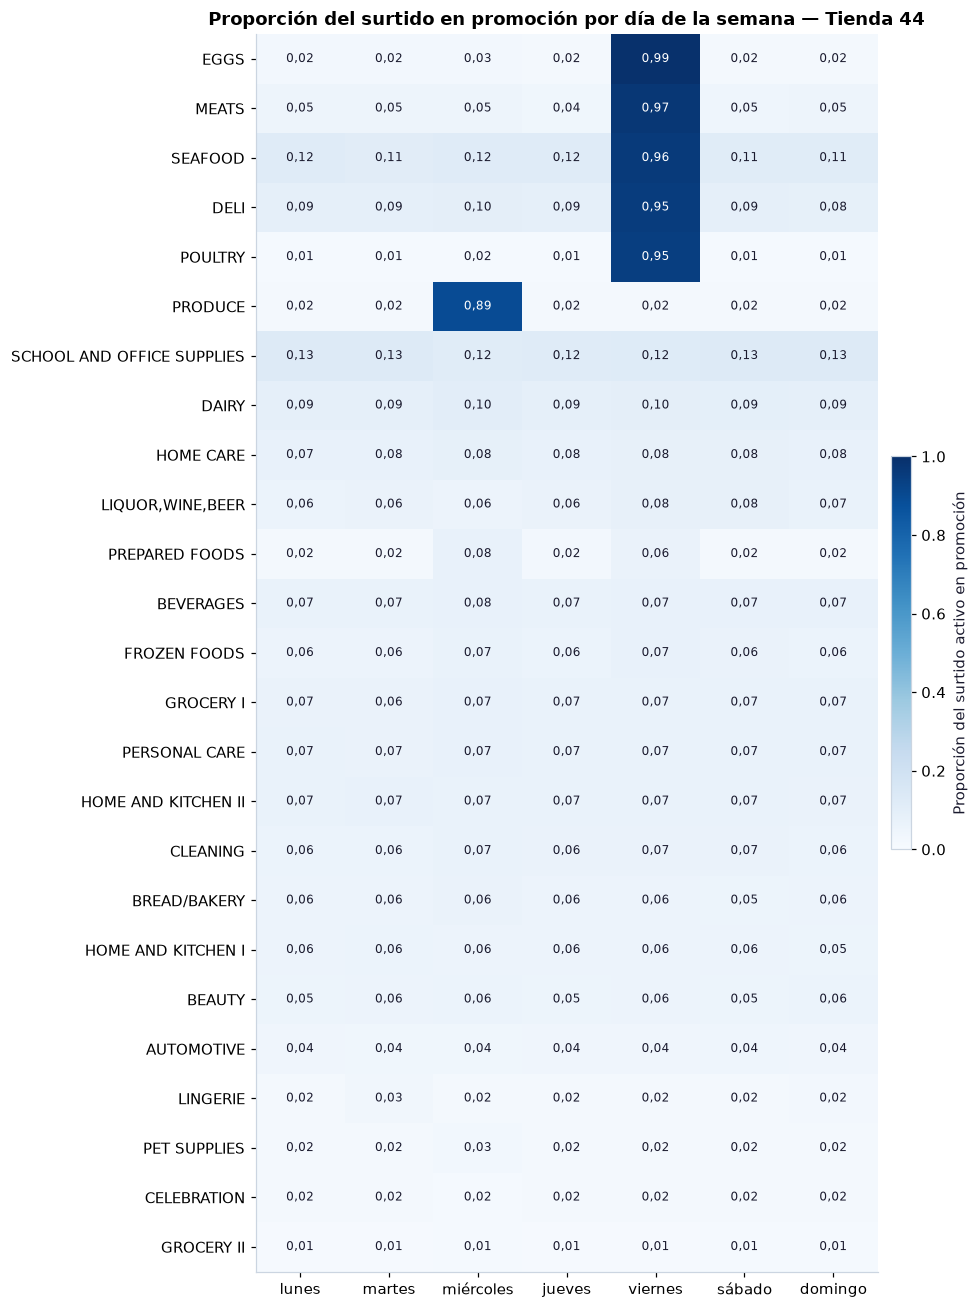

In [7]:
# Calcular la proporción media en promoción por familia y día de la semana (familias con al menos 10% de días)
dias_con_promo = intensidad.groupby("family", observed=True)["n_promo"].apply(lambda s: (s > 0).mean())
familias_heatmap = dias_con_promo.index[dias_con_promo >= 0.10]
matriz = (
    intensidad.loc[intensidad["family"].isin(familias_heatmap)]
    .pivot_table(index="family", columns="dow", values="p_prop", aggfunc="mean", observed=True)
    .rename(columns=nombre_dia)
)
matriz = matriz.loc[matriz.max(axis=1).sort_values(ascending=False).index]
matriz.round(3).to_csv(os.path.join(ruta_tablas, "tabla_02_promocion_por_dia.csv"))

# Dibujar el mapa de calor (una sola escala de azules: magnitud)
fig, ax = plt.subplots(figsize=(9, 0.42 * len(matriz) + 1.5))
imagen = ax.imshow(matriz.to_numpy(), cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(matriz.shape[1]), matriz.columns)
ax.set_yticks(range(matriz.shape[0]), matriz.index)
ax.grid(False)
for i in range(matriz.shape[0]):
    for j in range(matriz.shape[1]):
        valor = matriz.iat[i, j]
        ax.text(j, i, miles_punto(valor, dec=2), ha="center", va="center", fontsize=8,
                color="white" if valor > 0.6 else tinta)
barra = fig.colorbar(imagen, ax=ax, fraction=0.03, pad=0.02)
barra.set_label("Proporción del surtido activo en promoción")
ax.set_title("Proporción del surtido en promoción por día de la semana — Tienda 44")
plt.tight_layout()
fig.savefig(os.path.join(ruta_figuras, "figura_01_promocion_por_dia.png"), dpi=150, bbox_inches="tight")
plt.show()

## 3. Programas semanales fijos

Para cada familia con programa: el día, cuántos SKUs activos hay en promedio ese día, qué proporción está en promoción, y cuántos días tiene promociones **fuera** del programa, que son las que permiten estimar sus efectos (D‑26).

In [8]:
# Resumir los programas
en_programa = intensidad.loc[intensidad["dia_programa"]]
fuera_programa = intensidad.loc[~intensidad["dia_programa"]]
con_promo_fuera = fuera_programa.loc[fuera_programa["n_promo"] > 0].groupby("family", observed=True)
tabla_programas = pd.DataFrame(
    {
        "dia": en_programa.groupby("family", observed=True)["dow"].first().map(nombre_dia),
        "dias_programa": en_programa.groupby("family", observed=True).size(),
        "skus_activos_medio": en_programa.groupby("family", observed=True)["n_activos"].mean().round(1),
        "proporcion_en_promocion": en_programa.groupby("family", observed=True)["p_prop"].mean().round(3),
        "dias_con_promo_fuera": con_promo_fuera.size(),
        "skus_promo_fuera_medio": con_promo_fuera["n_promo"].mean().round(1),
    }
).dropna(subset=["dia"])
tabla_programas = tabla_programas.astype({"dias_programa": int, "dias_con_promo_fuera": int})
tabla_programas.to_csv(os.path.join(ruta_tablas, "tabla_03_programas.csv"))
print(tabla_programas.to_string())

pct_programa = 100 * panel["program_promotion"].sum() / panel["onpromotion"].sum()
print(f"\nEl {miles_punto(pct_programa, dec=1)}% de los SKU-días en promoción corresponde a programas fijos.")

               dia  dias_programa  skus_activos_medio  proporcion_en_promocion  dias_con_promo_fuera  skus_promo_fuera_medio
family                                                                                                                      
DELI       viernes             84                74.6                    0.951                   452                     7.4
EGGS       viernes             84                31.3                    0.994                   243                     1.6
MEATS      viernes             84                54.3                    0.969                   229                     5.4
POULTRY    viernes             84                47.0                    0.945                   151                     2.1
PRODUCE  miércoles             84               252.4                    0.893                   393                     7.4
SEAFOOD    viernes             84                 7.0                    0.959                   276                     1.5


## 4. Ventas en días con y sin promoción propia (descriptivo)

Media y mediana de la venta diaria por SKU (`unit_sales_ppml`, con ceros) en SKU‑días con y sin promoción propia, y proporción de días sin venta. Se excluyen la ventana del terremoto (D‑09) y los días de programa fijo, en los que la promoción es indistinguible del día de la semana (D‑26).

**No es un lift**: la diferencia mezcla el efecto de la promoción con el calendario en que se aplica y con qué SKUs se promocionan. Las unidades son kilos en los perecibles y unidades en el resto (M‑14), por eso se comparan razones dentro de cada familia y no niveles entre familias.

In [9]:
# Seleccionar la muestra comparable: sin ventana del terremoto ni días de programa completos (A-04)
muestra = panel.loc[~panel["ventana_terremoto"] & ~panel["dia_programa"]]

# Comparar los SKU-días con y sin promoción dentro de cada familia
comparacion = (
    muestra.groupby(["family", "onpromotion"], observed=True)
    .agg(
        sku_dias=("item_nbr", "size"),
        media=("unit_sales_ppml", "mean"),
        mediana=("unit_sales_ppml", "median"),
        pct_sin_venta=("con_registro", lambda s: 100 * (1 - s.mean())),
    )
    .unstack("onpromotion")
)
comparacion.columns = [f"{medida}_{'con' if promo else 'sin'}" for medida, promo in comparacion.columns]
comparacion = comparacion.astype(float)
comparacion["razon_medias"] = comparacion["media_con"] / comparacion["media_sin"]
comparacion = comparacion.loc[comparacion["sku_dias_con"] >= 100].sort_values("sku_dias_con", ascending=False).round(2)

comparacion.to_csv(os.path.join(ruta_tablas, "tabla_04_ventas_con_sin_promocion.csv"))
print(comparacion.to_string())

                            sku_dias_sin  sku_dias_con  media_sin  media_con  mediana_sin  mediana_con  pct_sin_venta_sin  pct_sin_venta_con  razon_medias
family                                                                                                                                                    
GROCERY I                       534899.0       39319.0       9.25      21.85         5.00        12.00              15.88               3.92          2.36
BEVERAGES                       246906.0       19838.0      19.16      44.97         7.00        18.00              15.90               5.15          2.35
CLEANING                        189558.0       13792.0       6.34      14.97         3.00         8.00              18.83               6.45          2.36
DAIRY                           102676.0       10774.0      13.34      17.01         9.00        12.00               5.40               2.40          1.28
PERSONAL CARE                    68298.0        5223.0       3.83     

## 5. Tráfico de la tienda

Transacciones diarias de la tienda 44 (número de boletas), con su media móvil de 7 días. La franja gris es la ventana del terremoto, excluida de la estimación (D‑09). El tráfico es la variable dependiente del modelo de la fase 3 (D‑12).

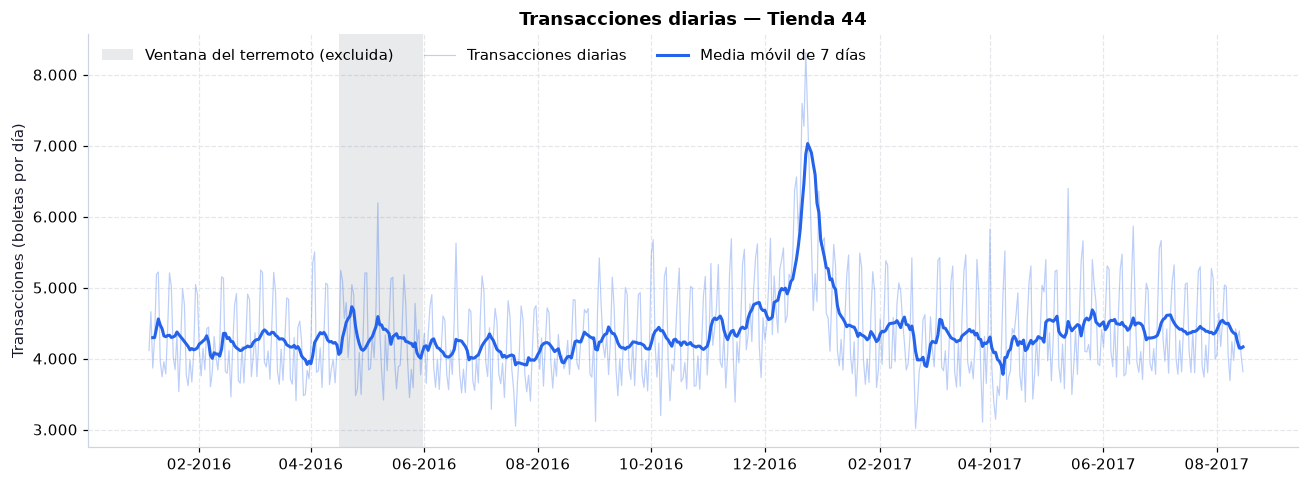

In [10]:
# Preparar la serie diaria de transacciones
trafico = calendario.set_index("date")["transactions"]
media_movil = trafico.rolling(7, min_periods=4).mean()
inicio_t, fin_t = calendario.loc[calendario["ventana_terremoto"], "date"].agg(["min", "max"])

# Dibujar la serie (un solo eje)
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.axvspan(inicio_t, fin_t, color=gris, alpha=0.15, lw=0, label="Ventana del terremoto (excluida)")
ax.plot(trafico.index, trafico, color=azul, alpha=0.3, lw=0.8, label="Transacciones diarias")
ax.plot(media_movil.index, media_movil, color=azul, lw=2, label="Media móvil de 7 días")
ax.yaxis.set_major_formatter(fmt_miles)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m-%Y"))
ax.set_title("Transacciones diarias — Tienda 44")
ax.set_ylabel("Transacciones (boletas por día)")
ax.legend(loc="upper left", ncol=3)
plt.tight_layout()
fig.savefig(os.path.join(ruta_figuras, "figura_02_transacciones.png"), dpi=150, bbox_inches="tight")
plt.show()

In [11]:
# Comparar las transacciones medias por tipo de día respecto de los días sin ninguna marca de calendario
marcas = [
    "dia_libre", "adicional", "dia_laboral_recuperado", "evento_comercial", "evento_otro", "dia_pago", "post_pago",
]
base = calendario.loc[~calendario["ventana_terremoto"]]
sin_marca = ~base[marcas].any(axis=1)
media_normal = base.loc[sin_marca, "transactions"].mean()

trafico_dias = pd.DataFrame(
    {
        "dias": [base[m].sum() for m in marcas] + [sin_marca.sum()],
        "transacciones_medias": [base.loc[base[m], "transactions"].mean() for m in marcas] + [media_normal],
    },
    index=marcas + ["sin marca"],
)
trafico_dias["razon_vs_sin_marca"] = trafico_dias["transacciones_medias"] / media_normal
trafico_dias = trafico_dias.round(2)

por_dia_semana = base.groupby("dow")["transactions"].mean().rename(index=nombre_dia).round(0)

trafico_dias.to_csv(os.path.join(ruta_tablas, "tabla_05_transacciones_por_tipo_de_dia.csv"))
por_dia_semana.to_csv(os.path.join(ruta_tablas, "tabla_06_transacciones_por_dia_semana.csv"))
print(trafico_dias.to_string())
print(por_dia_semana.to_string())

                        dias  transacciones_medias  razon_vs_sin_marca
dia_libre                 16               4694.69                1.09
adicional                  8               6576.12                1.53
dia_laboral_recuperado     1               5191.00                1.21
evento_comercial           2               4578.00                1.06
evento_otro                1               4717.00                1.10
dia_pago                  36               4262.78                0.99
post_pago                 70               4496.01                1.05
sin marca                415               4300.23                1.00
dow
lunes        3978.0
martes       3852.0
miércoles    4265.0
jueves       3822.0
viernes      4500.0
sábado       5133.0
domingo      5006.0


## 6. SKUs representativos

Venta diaria de un SKU por familia, con los días en promoción en naranja y los días sin venta en cero. Se muestran dos familias con programa fijo (MEATS, PRODUCE) y dos sin programa (LIQUOR,WINE,BEER, BEVERAGES). En cada familia se elige el SKU con más días con venta y, ante empate, más ventas totales.

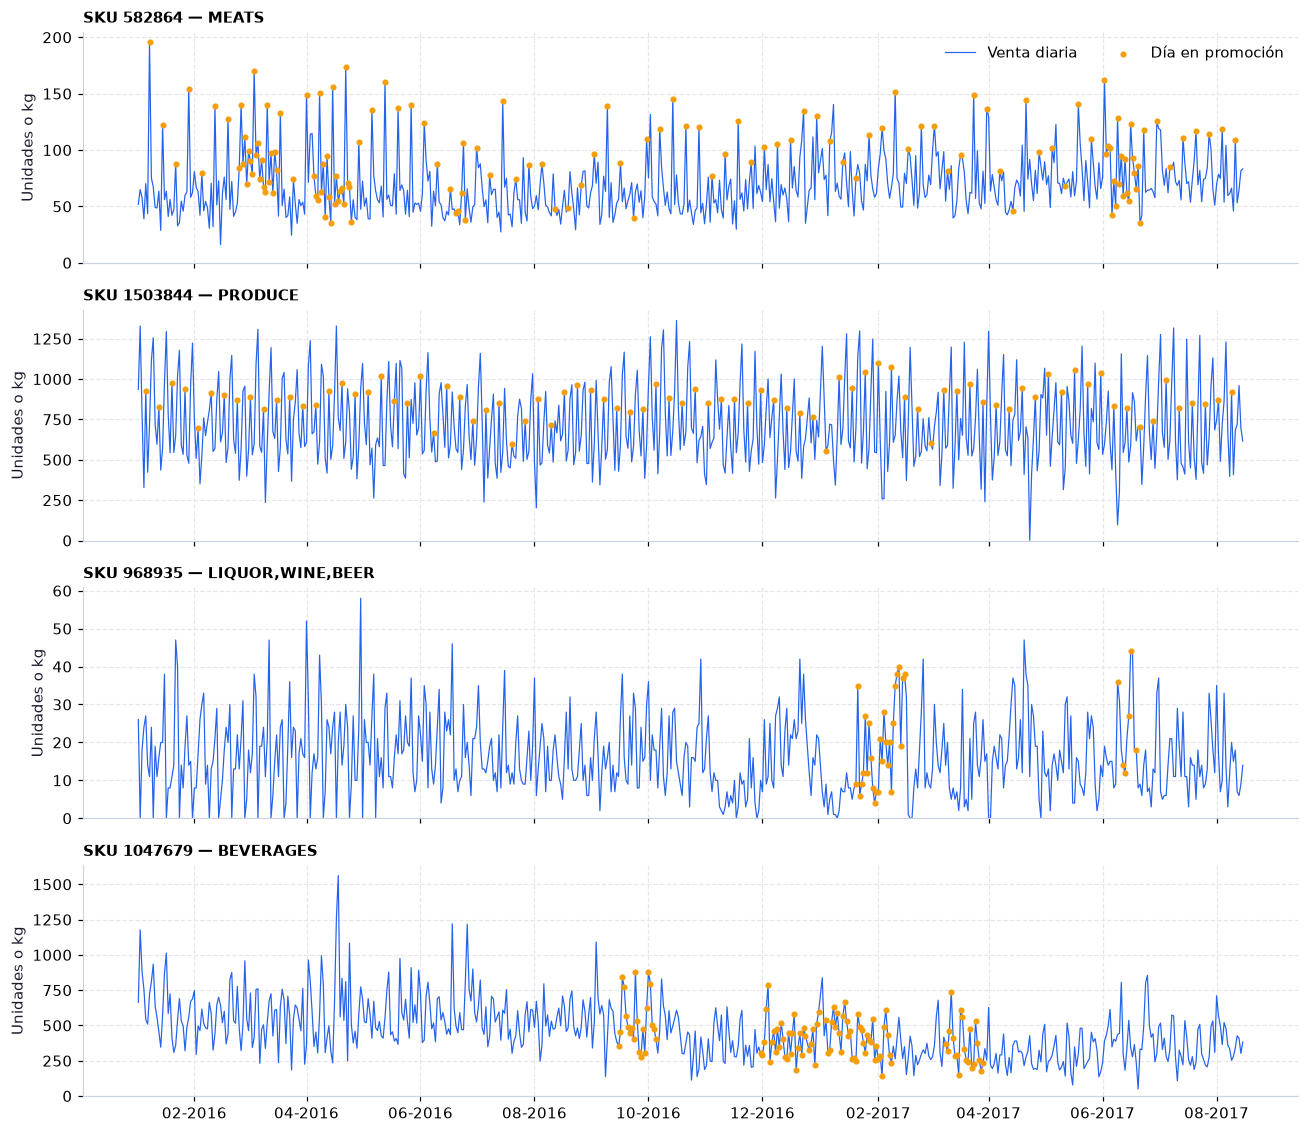

Tablas en resultados\tablas: ['tabla_01_universo.csv', 'tabla_02_promocion_por_dia.csv', 'tabla_03_programas.csv', 'tabla_04_ventas_con_sin_promocion.csv', 'tabla_05_transacciones_por_tipo_de_dia.csv', 'tabla_06_transacciones_por_dia_semana.csv']
Figuras en resultados\figuras: ['figura_01_promocion_por_dia.png', 'figura_02_transacciones.png', 'figura_03_skus_representativos.png']

>>>> Proceso finalizado <<<<


In [12]:
# Elegir un SKU por familia
familias_ejemplo = ["MEATS", "PRODUCE", "LIQUOR,WINE,BEER", "BEVERAGES"]
resumen_sku = (
    panel.loc[panel["family"].isin(familias_ejemplo)]
    .groupby(["family", "item_nbr"], observed=True)
    .agg(dias_con_venta=("con_registro", "sum"), ventas=("unit_sales_ppml", "sum"))
    .reset_index()
    .sort_values(["dias_con_venta", "ventas"], ascending=False)
)
ejemplos = resumen_sku.groupby("family", observed=True).head(1).set_index("family").loc[familias_ejemplo]

# Dibujar una serie por SKU (pequeños múltiplos, cada uno con su propio eje)
fig, axes = plt.subplots(nrows=len(ejemplos), ncols=1, figsize=(12, 2.6 * len(ejemplos)), sharex=True)
for ax, (familia, fila) in zip(axes, ejemplos.iterrows()):
    serie = panel.loc[panel["item_nbr"] == int(fila["item_nbr"])].set_index("date")
    promo = serie.loc[serie["onpromotion"]]
    ax.plot(serie.index, serie["unit_sales_ppml"], color=azul, lw=0.8, label="Venta diaria")
    ax.scatter(promo.index, promo["unit_sales_ppml"], color=naranja, s=9, zorder=3, label="Día en promoción")
    ax.set_title(f"SKU {int(fila['item_nbr'])} — {familia}", fontsize=10, loc="left")
    ax.set_ylabel("Unidades o kg")
    ax.set_ylim(bottom=0)
axes[0].legend(loc="upper right", ncol=2)
axes[-1].xaxis.set_major_locator(mdates.MonthLocator(interval=2))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%m-%Y"))
plt.tight_layout()
fig.savefig(os.path.join(ruta_figuras, "figura_03_skus_representativos.png"), dpi=150, bbox_inches="tight")
plt.show()

print(f"Tablas en {ruta_tablas}: {sorted(os.listdir(ruta_tablas))}")
print(f"Figuras en {ruta_figuras}: {sorted(os.listdir(ruta_figuras))}")

print(f"\n>>>> Proceso finalizado <<<<")